# Data import
What datasets are you using, later explain the variables a little bit more


In [1]:
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder


In [2]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje\klasifikacijski_modeli\combined
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5       

In [3]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

# Encoding the data
binary features are encoded using label encoding (0 and 1), 
while for categorical features one-hot encoding is used.
As for the numerical features, they are normilized using min-max scaling.

In [4]:
# combine the data
combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [5]:
# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])


# one-hot endocing the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

combined_data = pd.get_dummies(combined_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
combined_data[numeric_features] = scaler.fit_transform(combined_data[numeric_features])



# Training Support Vector Machine (SVM) Classifier


In [6]:
# Create a binary target variable
combined_data['Pass'] = (combined_data['G3'] >= 0.5).astype(int)
X = combined_data.drop(columns=['G3', 'Pass'])
y = combined_data['Pass']

In [7]:
# Spliting the data = 80% training, 20% testing
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [8]:
# Train an SVM Classifier
svm_model = SVC(kernel='rbf', random_state=42, probability=True)
svm_model.fit(X_train, y_train)

SVC(probability=True, random_state=42)

# Model Evaluation


In [9]:
# Predict on test data
y_pred = svm_model.predict(X_test)

In [10]:
# Evaluate the SVM Classifier
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

# Display confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

Accuracy: 0.7655502392344498
Precision: 0.7717391304347826
Recall: 0.9530201342281879
F1 Score: 0.8528528528528528
Confusion Matrix:
 [[ 18  42]
 [  7 142]]


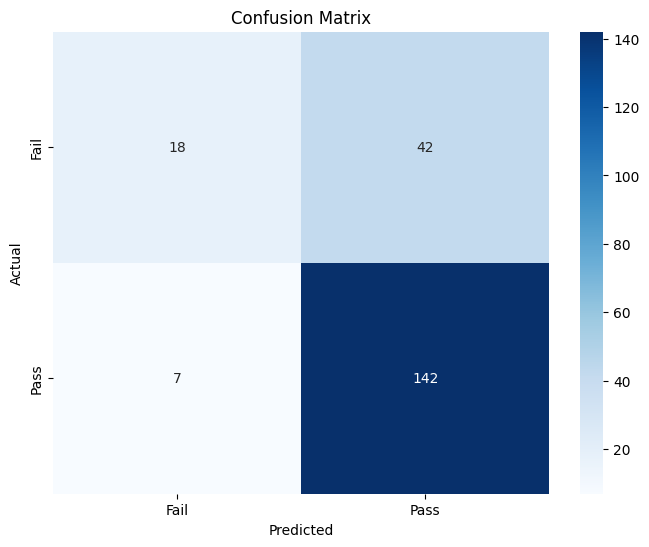

In [11]:
# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Fail', 'Pass'], yticklabels=['Fail', 'Pass'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()